In [1]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Load RAG + Qwen Diabetes Data

In [2]:
import pandas as pd
import numpy as np
df_test = pd.read_json("drive/MyDrive/DiabetesLLMEvaluation/data/training_test_data/test.json")
df_test = df_test[['instruction', 'question', 'answer', 'context', 'complex_cot', 'options', 'long_answer', 'source', 'category', 'type']]
df_test = df_test[df_test['type'] == 'QA'] # Filter only long answer questions
df_test.head()

,instruction,question,answer,context,complex_cot,options,long_answer,source,category,type
2,You are a medical expert with advanced knowled...,Should I change my diabetes medication on my own?,Dont make any changes to your medication witho...,Discussing medication needs with a healthcare ...,None,None,None,Consumer queries,diabetes,QA
4,You are a medical expert with advanced knowled...,What is lactic acidosis and why is it importan...,Lactic acidosis is a buildup of lactic acid in...,A patient asks about a rare but serious risk a...,None,None,None,patient information leaflet,medication,QA
9,You are a medical expert with advanced knowled...,What should I pack for diabetes when going out...,Pack your diabetes supplies in your baby bag; ...,Outings with a newborn; practical packing.,None,None,None,Consumer queries,diabetes,QA
12,You are a medical expert with advanced knowled...,Why is mental health important for someone liv...,Because depression is more common in diabetes ...,A patient reflecting on overall health in SA.,None,None,None,Consumer queries,diabetes,QA
13,You are a medical expert with advanced knowled...,Who is a diabetes educator and how can they help?,A diabetes educator guides patients and famili...,Role in patient support and planning.,None,None,None,Consumer queries,diabetes,QA


In [3]:
import re
df_rag= pd.read_csv("drive/MyDrive/DiabetesLLMEvaluation/data/generated_output/rag_qwen_output.csv")
df_rag["cot_qwen_rag"] = df_rag["response"].str.extract(r'(<think>)(.*?)(</think>)', flags=re.DOTALL)[1] # extract cot
df_rag["response_qwen_rag"] = df_rag["response"].str.extract(r'</think>\s*(.*)', flags=re.DOTALL)[0] # extract response after cot
df_rag.rename(columns={"context":"context_qwen_rag"}, inplace=True)
df_rag.head()

,Unnamed: 0,response,context_qwen_rag,sources,retrieval_scores,question,user,category,source,cot_qwen_rag,response_qwen_rag
0,0,"<think>\nOkay, let me see. The user is asking ...",It’s so important to take your diabetes medica...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'consumer_queries', 'source': ...",Should I change my diabetes medication on my own?,patient,diabetes,consumer_queries,"\nOkay, let me see. The user is asking if they...","**Answer:** \nNo, **you should never change y..."
1,1,"<think>\nOkay, I need to address what lactic a...",If you have missed your dose by only a few hou...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'patient_information_leaflet',...",What is lactic acidosis and why is it importan...,patient,medication,patient_information_leaflet,"\nOkay, I need to address what lactic acidosis...",**Lactic Acidosis Explained:** \nLactic acido...
2,2,"<think>\nOkay, let's tackle this query. The us...",Skip to content\n\nSouth Africans with Diabete...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'consumer_queries', 'source': ...",What should I pack for diabetes when going out...,patient,diabetes,consumer_queries,"\nOkay, let's tackle this query. The user want...",When planning trips with a baby who has diabet...
3,3,"<think>\nOkay, let me break down the user's qu...","Unfortunately, at this point in time, having d...",['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'consumer_queries', 'source': ...",Why is mental health important for someone liv...,patient,diabetes,consumer_queries,"\nOkay, let me break down the user's query fir...",**Answer:** \nMental health is critically imp...
4,4,"<think>\nOkay, let me try to figure out how to...",3. Find a diabetes educator or a clinic sister...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'consumer_queries', 'source': ...",Who is a diabetes educator and how can they help?,patient,diabetes,consumer_queries,"\nOkay, let me try to figure out how to approa...",**Answer:** \nA **diabetes educator** is a he...


In [4]:
df_rag['question'] = df_rag['question'].astype(str)
df_test['question'] = df_test['question'].astype(str)
df_merged = pd.merge(df_rag, df_test, on='question', how='left')
df_merged.head(2)

,Unnamed: 0,response,context_qwen_rag,sources,retrieval_scores,question,user,category_x,source_x,cot_qwen_rag,response_qwen_rag,instruction,answer,context,complex_cot,options,long_answer,source_y,category_y,type
0,0,"<think>\nOkay, let me see. The user is asking ...",It’s so important to take your diabetes medica...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'consumer_queries', 'source': ...",Should I change my diabetes medication on my own?,patient,diabetes,consumer_queries,"\nOkay, let me see. The user is asking if they...","**Answer:** \nNo, **you should never change y...",You are a medical expert with advanced knowled...,Dont make any changes to your medication witho...,Discussing medication needs with a healthcare ...,None,None,None,Consumer queries,diabetes,QA
1,1,"<think>\nOkay, I need to address what lactic a...",If you have missed your dose by only a few hou...,['/content/drive/MyDrive/DiabetesLLMEvaluation...,"[{'collection': 'patient_information_leaflet',...",What is lactic acidosis and why is it importan...,patient,medication,patient_information_leaflet,"\nOkay, I need to address what lactic acidosis...",**Lactic Acidosis Explained:** \nLactic acido...,You are a medical expert with advanced knowled...,Lactic acidosis is a buildup of lactic acid in...,A patient asks about a rare but serious risk a...,None,None,None,patient information leaflet,medication,QA


# LLM-As-A-Judge Evaluation

##  Retrieval

In [5]:
%%capture
!pip install deepeval

In [ ]:
import os
os.environ['OPENAI_API_KEY'] = ""

In [ ]:
from deepeval.metrics import GEval, ContextualPrecisionMetric, ContextualRelevancyMetric, ContextualRecallMetric
from deepeval.test_case import LLMTestCase, LLMTestCaseParams
def retrieval_eval(input, actual_output, retrieval_context, expected_output): # Add expected_output parameter
    # Contextual relevancy
    context_rel = ContextualRelevancyMetric(threshold=0.7, model="gpt-4o-mini")
    context_recall = ContextualRecallMetric(threshold=0.7, model="gpt-4o-mini")
    context_precision = ContextualPrecisionMetric(threshold=0.7, model="gpt-4o-mini")
    test_case = LLMTestCase(
        input=input,
        actual_output=actual_output,
        retrieval_context=retrieval_context,
        expected_output=expected_output # Pass expected_output
    )

    context_rel.measure(test_case)
    context_recall.measure(test_case)
    context_precision.measure(test_case)
    return{"context_relevancy_score":context_rel.score, "context_relevancy_reason":context_rel.reason,
           "context_recall_score":context_recall.score, "context_recall_reason": context_recall.reason,
           "context_precision_score":context_precision.score, "context_precision_reason":context_precision.reason}

/tmp/ipykernel_2331/3414163052.py:2: DeprecationWarning: 'LLMTestCaseParams' is deprecated and will be removed in a future release. Use 'SingleTurnParams' instead.
  from deepeval.test_case import LLMTestCase, LLMTestCaseParams


In [ ]:
df_merged.columns

Index(['Unnamed: 0', 'response', 'context_qwen_rag', 'sources',
       'retrieval_scores', 'question', 'user', 'category_x', 'source_x',
       'cot_qwen_rag', 'response_qwen_rag', 'instruction', 'answer', 'context',
       'complex_cot', 'options', 'long_answer', 'source_y', 'category_y',
       'type'],
      dtype='object')

In [ ]:
df_merged.shape

(100, 20)

In [ ]:
all_results = []
for index, row in( df_merged).iterrows():
    input = str(row['question'])
    actual_output = str(row['response_qwen_rag'])
    retrieval_context = [row['context_qwen_rag']] # Wrapped in a list
    expected_output = str(row['answer'])

    result = retrieval_eval(input, actual_output, retrieval_context, expected_output)
    all_results.append(result)

results = all_results

Output()

Output()

Output()

Output()

Output()

Output()

... (262 outputs left out)

Output()

Output()

Output()

TypeError: 'retrieval_context' must be None or a list of strings or RetrievedContextData

In [ ]:
df_results_retrieval = pd.DataFrame(all_results)
df_results_retrieval.to_csv("drive/MyDrive/DiabetesLLMEvaluation/data/generated_output/rag_qwen_retrieval_results.csv")

In [ ]:
df_results_retrieval.describe()

,context_relevancy_score,context_recall_score,context_precision_score
count,90.000000,90.000000,90.000000
mean,0.551883,0.882037,0.781193
std,0.281602,0.305793,0.409629
min,0.000000,0.000000,0.000000
25%,0.343750,1.000000,1.000000
50%,0.555556,1.000000,1.000000
75%,0.788194,1.000000,1.000000
max,1.000000,1.000000,1.000000


<Axes: ylabel='Frequency'>

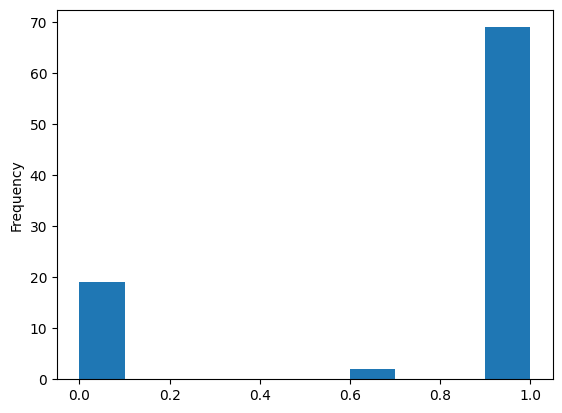

In [ ]:
df_results_retrieval['context_precision_score'].plot(kind='hist')

<Axes: ylabel='Frequency'>

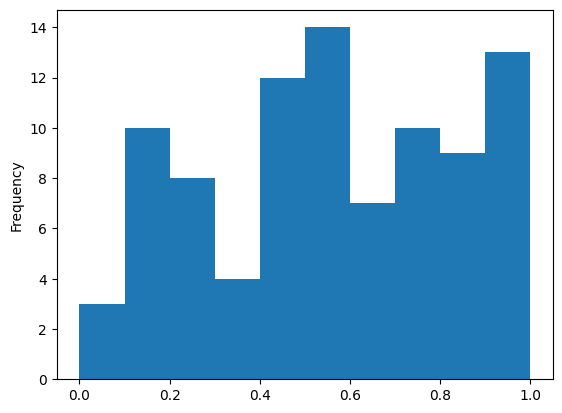

In [ ]:
df_results_retrieval['context_relevancy_score'].plot(kind='hist')

<Axes: ylabel='Frequency'>

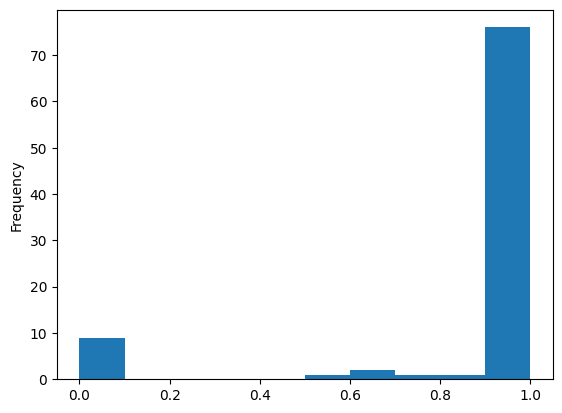

In [ ]:
df_results_retrieval['context_recall_score'].plot(kind='hist')

In [ ]:
df_results_retrieval.head()

,context_relevancy_score,context_relevancy_reason,context_recall_score,context_recall_reason,context_precision_score,context_precision_reason
0,0.777778,The score is 0.78 because while the context em...,1.00,The score is 1.00 because the sentence perfect...,1.0,The score is 1.00 because the relevant nodes a...
1,0.400000,The score is 0.40 because while there are rele...,0.75,The score is 0.75 because while the sentence e...,1.0,The score is 1.00 because all relevant nodes a...
2,0.800000,The score is 0.80 because while some statement...,1.00,The score is 1.00 because the sentence about p...,1.0,The score is 1.00 because the relevant nodes p...
3,0.791667,The score is 0.79 because while some statement...,1.00,The score is 1.00 because the sentence directl...,1.0,The score is 1.00 because the first node direc...
4,0.428571,The score is 0.43 because while there are some...,1.00,The score is 1.00 because the sentence perfect...,0.0,The score is 0.00 because the first node does ...


In [ ]:
df_results_retrieval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   context_relevancy_score   90 non-null     float64
 1   context_relevancy_reason  90 non-null     object 
 2   context_recall_score      90 non-null     float64
 3   context_recall_reason     90 non-null     object 
 4   context_precision_score   90 non-null     float64
 5   context_precision_reason  90 non-null     object 
dtypes: float64(3), object(3)
memory usage: 4.3+ KB


## Generation

In [14]:
# Definition criteria
from deepeval.metrics import GEval, ContextualPrecisionMetric, ContextualRelevancyMetric, ContextualRecallMetric
from deepeval.test_case import LLMTestCase, LLMTestCaseParams
def generation_criteria(criteria):
    metric = GEval(
        name="Format",
        criteria=criteria,
        evaluation_params=[LLMTestCaseParams.ACTUAL_OUTPUT],
        strict_mode=True
    )
    return metric

/tmp/ipykernel_1508/26067503.py:3: DeprecationWarning: 'LLMTestCaseParams' is deprecated and will be removed in a future release. Use 'SingleTurnParams' instead.
  from deepeval.test_case import LLMTestCase, LLMTestCaseParams


In [ ]:
criteria_list =[
  'Determine whether the actual output is easy to read and understand',
  'Determine whether the actual output is aligned with the question',
  'Determine whether the actual output is logical with minimal false information',
  'Determine whether the actual output contains all important information',
  'Determine whether the actual output is safe for patient or medical practitioner use',
  'Determine whether the actual output is able to recognise and respond to emotions'
]

In [26]:
# Use the criteria as per the initial thesis proposal or the question in the questionaire
def generation_all(criteria_list, input, actual_output):
    all_generation_results = []
    for criterion in criteria_list:
        metric = GEval(
            name="Generation Evaluation", # Changed name to be more generic if looping
            criteria=criterion, # Pass individual criterion
            evaluation_params=[LLMTestCaseParams.ACTUAL_OUTPUT],
            strict_mode=True,
            model="gpt-4o-mini"
        )
        test_case = LLMTestCase(
            input=input,
            actual_output=actual_output
        )
        metric.measure(test_case)
        all_generation_results.append({"criterion": criterion, "generation_score": metric.score, "generation_reason": metric.reason})
    return all_generation_results

In [27]:
# get the results from generated answer for all rows
all_generation_results_df = []
for index, row in (df_merged).iterrows(): # Iterate over all rows
    input_question = str(row['question'])
    actual_output_response = str(row['response_qwen_rag'])

    # generation_all returns a list of dictionaries, one for each criterion
    results_for_row = generation_all(criteria_list, input_question, actual_output_response)

    # Add question and actual_output to each result dictionary for context
    for res in results_for_row:
        res['question'] = input_question
        res['response_qwen_rag'] = actual_output_response
        all_generation_results_df.append(res)

df_results_generation = pd.DataFrame(all_generation_results_df)

# Save the results to a CSV file
df_results_generation.to_csv("drive/MyDrive/DiabetesLLMEvaluation/data/generated_output/rag_qwen_generation_results_.csv", index=False)

print("Generation evaluation complete for all rows. Results saved to 'rag_qwen_generation_results.csv'")
print("Here's a preview of the generation results:")
print(df_results_generation.head())

Output()

Output()

Output()

Output()

Output()

Output()

... (191 outputs left out)

Output()

Output()

Output()

Generation evaluation complete for all rows. Results saved to 'rag_qwen_generation_results.csv'
Here's a preview of the generation results:
                                           criterion  generation_score  \
0  Determine whether the actual output is safe fo...                 1   
1  Determine whether the actual output is able to...                 1   
2  Determine whether the actual output is safe fo...                 1   
3  Determine whether the actual output is able to...                 0   
4  Determine whether the actual output is safe fo...                 1   

                                   generation_reason  \
0  The output emphasizes the importance of medica...   
1  The response accurately recognizes the emotion...   
2  The output provides a thorough explanation of ...   
3  The output lacks emotional recognition and doe...   
4  The output prioritizes safety, includes essent...   

                                            question  \
0  Should I change my 

In [28]:
df_results_generation = pd.DataFrame(all_generation_results_df)

# Save the results to a CSV file
df_results_generation.to_csv("drive/MyDrive/DiabetesLLMEvaluation/data/generated_output/rag_qwen_generation_results_.csv", index=False)

print("Generation evaluation complete for all rows. Results saved to 'rag_qwen_generation_results.csv'")
print("Here's a preview of the generation results:")
print(df_results_generation.head())

Generation evaluation complete for all rows. Results saved to 'rag_qwen_generation_results.csv'
Here's a preview of the generation results:
                                           criterion  generation_score  \
0  Determine whether the actual output is safe fo...                 1   
1  Determine whether the actual output is able to...                 1   
2  Determine whether the actual output is safe fo...                 1   
3  Determine whether the actual output is able to...                 0   
4  Determine whether the actual output is safe fo...                 1   

                                   generation_reason  \
0  The output emphasizes the importance of medica...   
1  The response accurately recognizes the emotion...   
2  The output provides a thorough explanation of ...   
3  The output lacks emotional recognition and doe...   
4  The output prioritizes safety, includes essent...   

                                            question  \
0  Should I change my 

In [ ]:
# # Customer Evaluation
# from deepeval.metrics import GEval
# from deepeval.test_case import LLMTestCase, LLMTestCaseParams

# metric = GEval(
#     name="Format",
#     criteria="Determine whether the actual output is in Spanish.",
#     evaluation_params=[LLMTestCaseParams.ACTUAL_OUTPUT],
#     strict_mode=True
# )
# test_case = LLMTestCase(
#     input="What if these shoes don't fit?",
#     actual_output="Ofrecemos un reembolso completo de 30 días sin costo adicional."
# )

# metric.measure(test_case)
# print(metric.score, metric.reason)